<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_physics/statphys_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Physics* — `statphys_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Statistical Physics — Chapter 2 Figures

Run this notebook in Google Colab. All figures are saved to `figures/` (created automatically).

**Figure list:**
1. `fig_maxwell_distribution.png` — Maxwell speed distribution (He, Ne, Ar, Xe)
2. `fig_ideal_gas_deviations.png` — pV/NkT deviations from ideal gas law
3. `fig_diatomic_heat_capacity.png` — H₂ heat capacity vs temperature
4. `fig_interaction_potential.png` — Lennard-Jones and hard-core potentials
5. `fig_mayer_f.png` — Mayer f-function
6. `fig_vdw_isotherms.png` — van der Waals p-V isotherms
7. `fig_debye_screening.png` — Coulomb vs screened (Yukawa) potential

**Usage:** Copy the `figures/` folder to the same directory as your `.qmd` file.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import ScalarFormatter
import os

os.makedirs('figures', exist_ok=True)

# ── Global style ────────────────────────────────────────────────────────────
DARK_BG   = '#1a1a2e'
PANEL_BG  = '#16213e'
BLUE      = '#7ec8e3'
YELLOW    = '#f9c74f'
GREEN     = '#90ee90'
RED       = '#e07070'
PURPLE    = '#b39ddb'
ORANGE    = '#ffb347'
DIM       = '#aaaaaa'

def base_style():
    plt.rcParams.update({
        'figure.facecolor':  DARK_BG,
        'axes.facecolor':    PANEL_BG,
        'axes.edgecolor':    DIM,
        'axes.labelcolor':   DIM,
        'axes.titlecolor':   BLUE,
        'xtick.color':       DIM,
        'ytick.color':       DIM,
        'text.color':        DIM,
        'grid.color':        '#2a2a4e',
        'grid.linestyle':    '--',
        'grid.alpha':        0.6,
        'legend.facecolor':  PANEL_BG,
        'legend.edgecolor':  DIM,
        'legend.labelcolor': DIM,
        'font.family':       'sans-serif',
        'font.size':         11,
        'axes.titlesize':    13,
        'axes.labelsize':    11,
        'legend.fontsize':   10,
        'lines.linewidth':   2.0,
        'savefig.facecolor': DARK_BG,
        'savefig.dpi':       200,
        'savefig.bbox':      'tight',
    })

base_style()
print('Style configured. Figures will be saved to ./figures/')


Style configured. Figures will be saved to ./figures/


## Figure 1 — Maxwell Speed Distribution

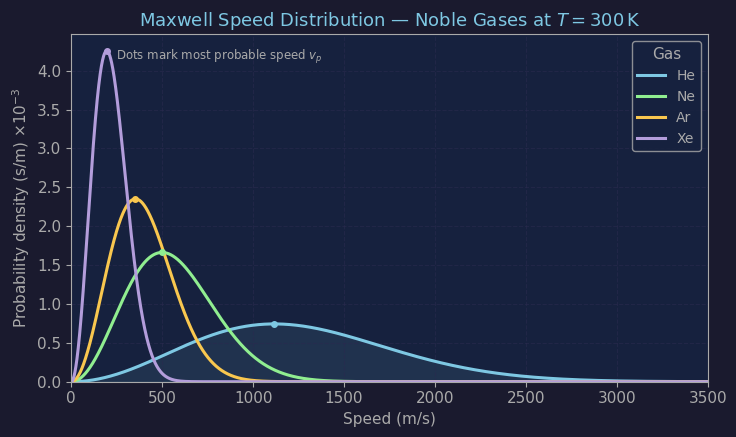

Saved: figures/fig_maxwell_distribution.png


In [2]:
base_style()

# --- constants ---
kB  = 1.380649e-23   # J/K
amu = 1.66054e-27    # kg
T   = 300.0

gases = [
    ('He',   4,   BLUE),
    ('Ne',   20,  GREEN),
    ('Ar',   40,  YELLOW),
    ('Xe',   131, PURPLE),
]

v = np.linspace(0, 3500, 4000)

fig, ax = plt.subplots(figsize=(7.5, 4.5))

for name, mass_amu, color in gases:
    m = mass_amu * amu
    A = 4 * np.pi * (m / (2 * np.pi * kB * T))**1.5
    f = A * v**2 * np.exp(-m * v**2 / (2 * kB * T))

    # ✔ 최적 스케일: ×10^3
    f_scaled = f * 1e3

    ax.plot(v, f_scaled, color=color, label=name, linewidth=2.2)

    # most probable speed
    v_p = np.sqrt(2 * kB * T / m)
    f_p = (A * v_p**2 * np.exp(-1.0)) * 1e3
    ax.plot(v_p, f_p, 'o', color=color, markersize=4, zorder=5)

# --- He shading ---
m_he = 4 * amu
A_he = 4 * np.pi * (m_he / (2 * np.pi * kB * T))**1.5
f_he = A_he * v**2 * np.exp(-m_he * v**2 / (2 * kB * T))
ax.fill_between(v, f_he * 1e3, alpha=0.10, color=BLUE)

# --- labels ---
ax.set_xlabel('Speed (m/s)')
ax.set_ylabel(r'Probability density (s/m) $\times 10^{-3}$')

# --- formatting ---
ax.set_title(r'Maxwell Speed Distribution — Noble Gases at $T=300\,\mathrm{K}$')
ax.set_xlim(0, 3500)
ax.set_ylim(0)

# ✔ offset 제거 (핵심!)
ax.ticklabel_format(axis='y', style='plain')

ax.legend(loc='upper right', title='Gas')
ax.grid(True)

# annotation
ax.text(0.07, 0.96,
        r'Dots mark most probable speed $v_p$',
        transform=ax.transAxes,
        fontsize=8.5, va='top')

fig.tight_layout()
fig.savefig('figures/fig_maxwell_distribution.png')
plt.show()

print('Saved: figures/fig_maxwell_distribution.png')

## Figure 2 — Deviations from the Ideal Gas Law

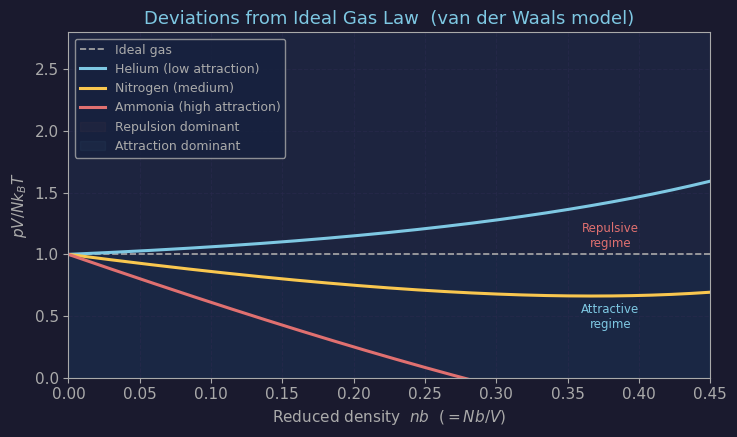

Saved: figures/fig_ideal_gas_deviations.png


In [3]:
base_style()

# Schematic pV/NkT vs reduced density using van der Waals model
# p = nkT/(1-nb) - an^2  =>  pV/NkT = 1/(1-nb) - an/kT
# x = nb (reduced density), a_star = a/(kT*b)

x = np.linspace(0, 0.45, 400)

gas_params = [
    ('Helium (low attraction)',   0.5,  BLUE),
    ('Nitrogen (medium)',         2.5,  YELLOW),
    ('Ammonia (high attraction)', 5.0,  RED),
]

fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.axhline(1, color=DIM, linestyle='--', linewidth=1.2, label='Ideal gas')

for label, astar, color in gas_params:
    ratio = 1.0 / (1 - x) - astar * x
    ax.plot(x, ratio, color=color, label=label, linewidth=2.2)

# Shade region > ideal and < ideal
ax.axhspan(1, 2.8, alpha=0.04, color=RED, label='Repulsion dominant')
ax.axhspan(0, 1,   alpha=0.04, color=BLUE, label='Attraction dominant')

ax.set_xlabel(r'Reduced density  $nb$  ($= Nb/V$)')
ax.set_ylabel(r'$pV / Nk_BT$')
ax.set_title('Deviations from Ideal Gas Law  (van der Waals model)')
ax.set_xlim(0, 0.45)
ax.set_ylim(0, 2.8)
ax.legend(loc='upper left', fontsize=9)
ax.grid(True)

# Annotations
ax.text(0.38, 1.06, 'Repulsive\nregime', color=RED, fontsize=8.5, ha='center')
ax.text(0.38, 0.40, 'Attractive\nregime', color=BLUE, fontsize=8.5, ha='center')

fig.tight_layout()
fig.savefig('figures/fig_ideal_gas_deviations.png')
plt.show()
print('Saved: figures/fig_ideal_gas_deviations.png')


## Figure 3 — Diatomic Gas Heat Capacity (H₂)

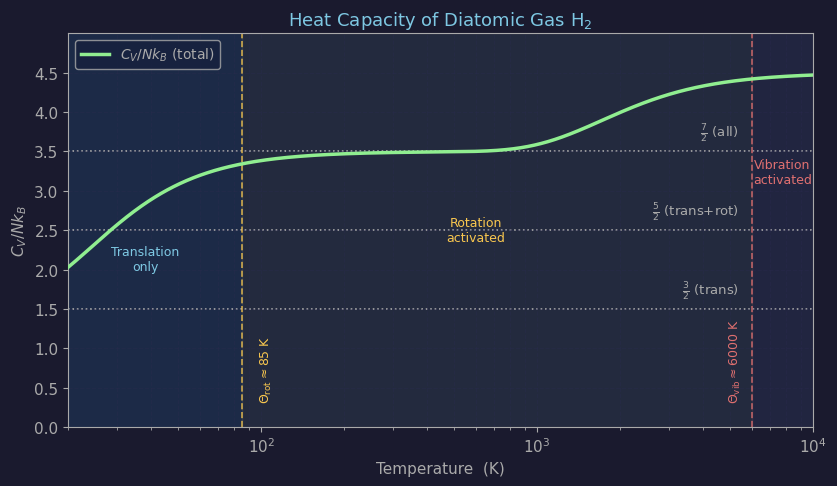

Saved: figures/fig_diatomic_heat_capacity.png


In [4]:
base_style()

# Parameters for H2
Theta_rot = 85.0    # K
Theta_vib = 6000.0  # K

T = np.logspace(np.log10(20), np.log10(10000), 2000)

# Translational: 3/2 Nk_B (constant)
C_trans = 1.5 * np.ones_like(T)

# Rotational (Einstein-like two-mode approximation)
u_rot = Theta_rot / T
C_rot = 2 * (u_rot**2 * np.exp(u_rot) / (np.exp(u_rot) - 1)**2)

# Vibrational (quantum harmonic oscillator, 1 mode pair)
u_vib = Theta_vib / T
C_vib = (u_vib**2 * np.exp(u_vib)) / (np.exp(u_vib) - 1)**2

C_total = C_trans + C_rot + C_vib
# C_total reaches ~4.47 at 10000 K  => extend ylim to 5.0

YLIM_TOP    = 5.0
XLIM_RIGHT  = 10000

fig, ax = plt.subplots(figsize=(8.5, 5.0))

ax.plot(T, C_total, color=GREEN, linewidth=2.5,
        label=r'$C_V / Nk_B$ (total)', zorder=3)

# Shade temperature regimes
ax.axvspan(20,        Theta_rot,  alpha=0.06, color=BLUE,   zorder=0)
ax.axvspan(Theta_rot, Theta_vib,  alpha=0.06, color=YELLOW, zorder=0)
ax.axvspan(Theta_vib, XLIM_RIGHT, alpha=0.06, color=RED,    zorder=0)

# Plateau dashed lines
for level, lbl in [(1.5, r'$\frac{3}{2}$ (trans)'),
                   (2.5, r'$\frac{5}{2}$ (trans+rot)'),
                   (3.5, r'$\frac{7}{2}$ (all)')]:
    ax.axhline(level, color=DIM, linestyle=':', linewidth=1.2, zorder=1)
    # Use get_yaxis_transform(): x is axes fraction (0-1), y is data units
    # x=0.96 => 4% gap from right spine; always inside, never clipped
    ax.text(0.90, level + 0.09, lbl,
            transform=ax.get_yaxis_transform(),
            color=DIM, fontsize=9.5, ha='right', va='bottom')

# Characteristic temperature markers
ax.axvline(Theta_rot, color=YELLOW, linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(Theta_rot * 1.15, 0.30,
        r'$\Theta_{\rm rot}\approx 85$ K',
        color=YELLOW, fontsize=9, rotation=90, va='bottom')

ax.axvline(Theta_vib, color=RED, linestyle='--', linewidth=1.2, alpha=0.8)
# Place Theta_vib label to the LEFT of the vline to stay away from right edge
ax.text(Theta_vib * 0.87, 0.30,
        r'$\Theta_{\rm vib}\approx 6000$ K',
        color=RED, fontsize=9, rotation=90, va='bottom', ha='center')

# Region labels — log-midpoints of each zone
ax.text(38,   2.0,  'Translation\nonly',   color=BLUE,   fontsize=9, ha='center')
ax.text(600,  2.36,  'Rotation\nactivated', color=YELLOW, fontsize=9, ha='center')
vib_x = 10 ** ((np.log10(Theta_vib) + np.log10(XLIM_RIGHT)) / 2)  # ~7746 K
ax.text(vib_x, 3.1, 'Vibration\nactivated', color=RED, fontsize=9, ha='center')

ax.set_xscale('log')
ax.set_xlabel('Temperature  (K)')
ax.set_ylabel(r'$C_V / Nk_B$')
ax.set_title(r'Heat Capacity of Diatomic Gas H$_2$')
ax.set_xlim(20, XLIM_RIGHT)
ax.set_ylim(0, YLIM_TOP)
ax.set_yticks([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5])
ax.grid(True, which='both', alpha=0.4)
ax.legend(loc='upper left')

fig.tight_layout()
fig.savefig('figures/fig_diatomic_heat_capacity.png')
plt.show()
print('Saved: figures/fig_diatomic_heat_capacity.png')


## Figure 4 — Interparticle Potential (Lennard-Jones and Hard-Core)

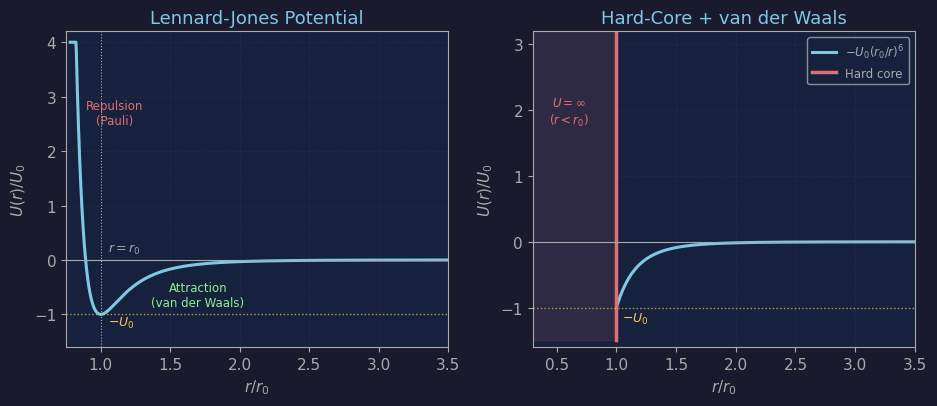

Saved: figures/fig_interaction_potential.png


In [5]:
base_style()

r0 = 1.0
U0 = 1.0

r_lj = np.linspace(0.78 * r0, 3.5 * r0, 1000)
U_lj = U0 * ((r0 / r_lj)**12 - 2 * (r0 / r_lj)**6)  # min at r=r0, value = -U0

r_hc = np.linspace(1.0 * r0, 3.5 * r0, 500)
U_hc = -U0 * (r0 / r_hc)**6

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))

# --- Left: Lennard-Jones ---
ax = axes[0]
U_plot = np.clip(U_lj, -1.5 * U0, 4 * U0)
ax.plot(r_lj / r0, U_plot / U0, color=BLUE, linewidth=2.2)
ax.axhline(0,  color=DIM,    linewidth=0.8, linestyle='-')
ax.axhline(-1, color=YELLOW, linewidth=1.0, linestyle=':', alpha=0.7)
ax.axvline(1,  color=DIM,    linewidth=0.8, linestyle=':')
ax.text(1.05, -1.22, r'$-U_0$',       color=YELLOW, fontsize=9)
ax.text(1.05,  0.15, r'$r = r_0$',    color=DIM,    fontsize=9)
ax.set_xlabel(r'$r / r_0$')
ax.set_ylabel(r'$U(r) / U_0$')
ax.set_title('Lennard-Jones Potential')
ax.set_xlim(0.75, 3.5)
ax.set_ylim(-1.6, 4.2)
ax.annotate('Repulsion\n(Pauli)',          xy=(1.1, 2.5), color=RED,   fontsize=8.5, ha='center')
ax.annotate('Attraction\n(van der Waals)', xy=(1.7,  -0.85), color=GREEN, fontsize=8.5, ha='center')
ax.grid(True)

# --- Right: Hard-core + vdW ---
ax = axes[1]
r_wall = np.array([r0, r0])
U_wall = np.array([-1.5 * U0, 4.5 * U0])
ax.plot(r_hc  / r0, U_hc  / U0, color=BLUE, linewidth=2.2, label=r'$-U_0(r_0/r)^6$')
ax.plot(r_wall / r0, U_wall / U0, color=RED,  linewidth=2.5, label='Hard core')
ax.fill_betweenx([-1.5, 4.5], 0, 1.0, color=RED, alpha=0.12)
ax.axhline(0,  color=DIM,    linewidth=0.8)
ax.axhline(-1, color=YELLOW, linewidth=1.0, linestyle=':', alpha=0.7)
ax.text(1.05, -1.22, r'$-U_0$', color=YELLOW, fontsize=9)
ax.text(0.6, 1.8, r'$U = \infty$' + '\n' + r'$(r < r_0)$',
        color=RED, fontsize=8.5, ha='center')
ax.set_xlabel(r'$r / r_0$')
ax.set_ylabel(r'$U(r) / U_0$')
ax.set_title('Hard-Core + van der Waals')
ax.set_xlim(0.3, 3.5)
ax.set_ylim(-1.6, 3.2)
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_interaction_potential.png')
plt.show()
print('Saved: figures/fig_interaction_potential.png')


## Figure 5 — Mayer f-Function

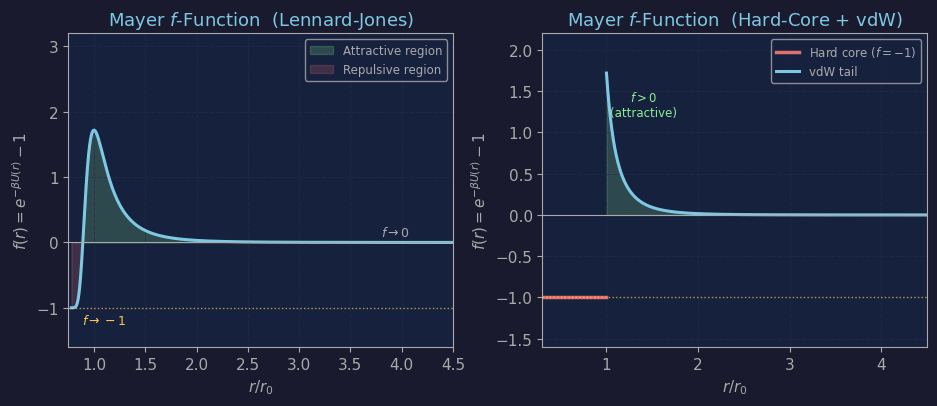

Saved: figures/fig_mayer_f.png


In [6]:
base_style()

r0   = 1.0
U0   = 1.0
beta = 1.0  # kBT = 1

r = np.linspace(0.78 * r0, 4.5 * r0, 2000)

# LJ potential
U_lj = U0 * ((r0 / r)**12 - 2 * (r0 / r)**6)
f_lj = np.exp(-beta * U_lj) - 1

# Hard-core + vdW
r2     = np.linspace(1.0 * r0, 4.5 * r0, 1500)
U_hc   = -U0 * (r0 / r2)**6
f_hc   = np.exp(-beta * U_hc) - 1
r_left = np.linspace(0.3 * r0, 1.0 * r0, 100)
f_hc_left = np.full(100, -1.0)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharey=False)

# --- Left: LJ Mayer f ---
ax = axes[0]
f_clip  = np.clip(f_lj, -1.5, 5)
r_plot  = r / r0
ax.plot(r_plot, f_clip, color=BLUE, linewidth=2.2)
ax.axhline(0,  color=DIM,    linewidth=0.8)
ax.axhline(-1, color=YELLOW, linewidth=1.0, linestyle=':', alpha=0.7)
ax.fill_between(r_plot, 0, f_clip, where=(f_clip  > 0), color=GREEN, alpha=0.20, label='Attractive region')
ax.fill_between(r_plot, f_clip, 0, where=(f_clip  < 0), color=RED,   alpha=0.20, label='Repulsive region')
ax.text(3.8,  0.10, r'$f \to 0$',  color=DIM,    fontsize=9)
ax.text(0.88, -1.25, r'$f \to -1$', color=YELLOW, fontsize=9)
ax.set_xlabel(r'$r / r_0$')
ax.set_ylabel(r'$f(r) = e^{-\beta U(r)} - 1$')
ax.set_title('Mayer $f$-Function  (Lennard-Jones)')
ax.set_xlim(0.75, 4.5)
ax.set_ylim(-1.6, 3.2)
ax.legend(fontsize=8.5)
ax.grid(True)

# --- Right: Hard-core + vdW Mayer f ---
ax = axes[1]
ax.plot(r_left / r0, f_hc_left, color=RED,  linewidth=2.5, label=r'Hard core ($f = -1$)')
ax.plot(r2     / r0, f_hc,      color=BLUE, linewidth=2.2, label='vdW tail')
ax.axhline(0,  color=DIM,    linewidth=0.8)
ax.axhline(-1, color=YELLOW, linewidth=1.0, linestyle=':', alpha=0.7)
ax.fill_between(r2 / r0, 0,    f_hc, where=(f_hc > 0), color=GREEN,  alpha=0.20)
ax.fill_between(r2 / r0, f_hc, 0,    where=(f_hc < 0), color=ORANGE, alpha=0.20)
ax.text(1.4, 1.2, r'$f > 0$' + '\n(attractive)', color=GREEN, fontsize=8.5, ha='center')
ax.set_xlabel(r'$r / r_0$')
ax.set_ylabel(r'$f(r) = e^{-\beta U(r)} - 1$')
ax.set_title('Mayer $f$-Function  (Hard-Core + vdW)')
ax.set_xlim(0.3, 4.5)
ax.set_ylim(-1.6, 2.2)
ax.legend(fontsize=8.5)
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_mayer_f.png')
plt.show()
print('Saved: figures/fig_mayer_f.png')


## Figure 6 — Van der Waals p-V Isotherms

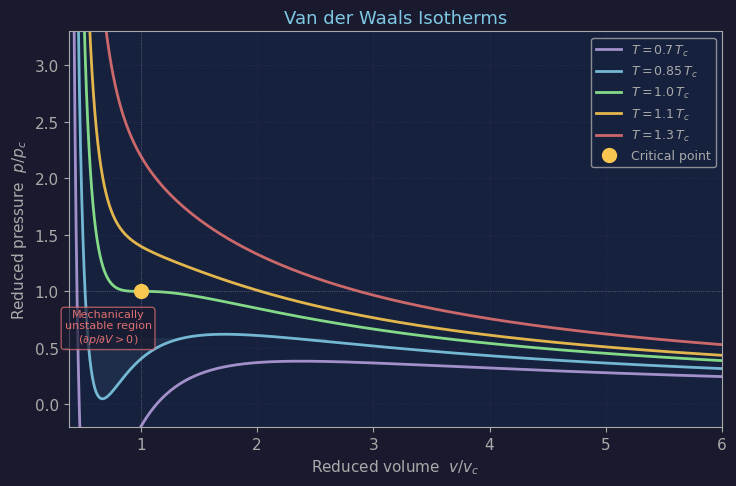

Saved: figures/fig_vdw_isotherms.png


In [7]:
base_style()

# Reduced vdW equation of state:
# (p_r + 3/v_r^2)(3*v_r - 1) = 8*t

v_r = np.linspace(0.38, 6.0, 5000)

T_vals    = [0.7, 0.85, 1.0, 1.1, 1.3]  # in units of Tc
colors_T  = [PURPLE, BLUE, GREEN, YELLOW, RED]
# FIX: avoid invalid escape \, inside f-string by building label separately
labels_T  = [r'$T = $' + f'{t}' + r'$\,T_c$' for t in T_vals]

fig, ax = plt.subplots(figsize=(7.5, 5.0))

for t, color, label in zip(T_vals, colors_T, labels_T):
    p_r = 8 * t / (3 * v_r - 1) - 3 / v_r**2
    p_r = np.where(v_r > 1.0 / 3.0 + 0.02, p_r, np.nan)
    p_r_plot = np.clip(p_r, -0.5, 3.5)
    ax.plot(v_r, p_r_plot, color=color, linewidth=2.0, label=label, alpha=0.9)

# Highlight unstable region for T=0.85 (rough Maxwell equal-area guide)
t_sub = 0.85
p_sub = 8 * t_sub / (3 * v_r - 1) - 3 / v_r**2
p_sub = np.where(v_r > 1.0 / 3.0 + 0.02, p_sub, np.nan)
mask = (v_r > 0.55) & (v_r < 2.6) & np.isfinite(p_sub)
ax.fill_between(v_r[mask], p_sub[mask], 0.58,
                where=p_sub[mask] < 0.58,
                color=BLUE, alpha=0.08, zorder=0)

# Mark critical point
ax.plot(1.0, 1.0, 'o', color=YELLOW, markersize=10, zorder=5,
        label='Critical point')
ax.axhline(1.0, color=DIM, linewidth=0.6, linestyle=':', alpha=0.5)
ax.axvline(1.0, color=DIM, linewidth=0.6, linestyle=':', alpha=0.5)

ax.set_xlabel(r'Reduced volume  $v / v_c$')
ax.set_ylabel(r'Reduced pressure  $p / p_c$')
ax.set_title('Van der Waals Isotherms')
ax.set_xlim(0.38, 6.0)
ax.set_ylim(-0.2, 3.3)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True)

# Annotation for unphysical region (FIX: use r-string, no \\partial needed)
ax.annotate(r'Mechanically' + '\n' + r'unstable region' + '\n' +
            r'($\partial p/\partial V > 0$)',
            xy=(0.72, 0.55), fontsize=8, color=RED, ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor=DARK_BG,
                      edgecolor=RED, alpha=0.7))

fig.tight_layout()
fig.savefig('figures/fig_vdw_isotherms.png')
plt.show()
print('Saved: figures/fig_vdw_isotherms.png')


## Figure 7 — Debye Screening (Coulomb vs Yukawa)

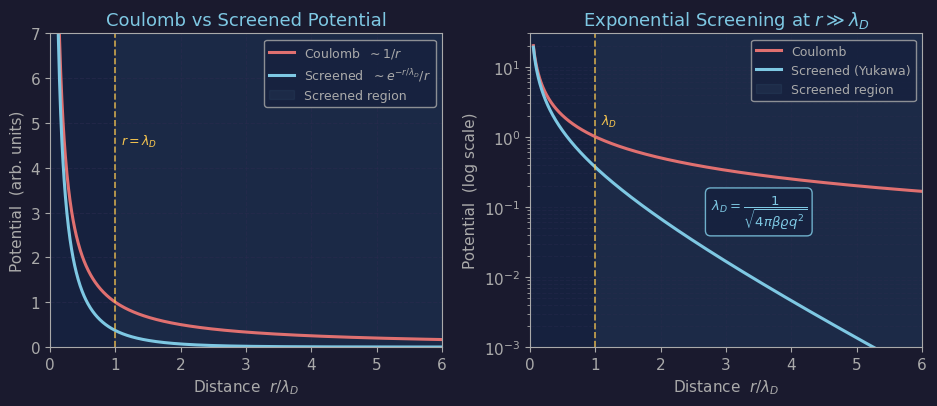

Saved: figures/fig_debye_screening.png


In [8]:
base_style()

r = np.linspace(0.05, 6.0, 1000)  # in units of lambda_D

U_coulomb = 1.0 / r
U_yukawa  = np.exp(-r) / r

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))

# --- Left: potential vs distance ---
ax = axes[0]
ax.plot(r, U_coulomb, color=RED,  linewidth=2.2, label=r'Coulomb  $\sim 1/r$')
ax.plot(r, U_yukawa,  color=BLUE, linewidth=2.2,
        label=r'Screened  $\sim e^{-r/\lambda_D}/r$')
ax.axvline(1.0, color=YELLOW, linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(1.08, 4.5, r'$r = \lambda_D$', color=YELLOW, fontsize=9)
# shade screening region
ax.axvspan(1, 6, alpha=0.05, color=BLUE, label='Screened region')
ax.set_xlabel(r'Distance  $r / \lambda_D$')
ax.set_ylabel(r'Potential  (arb. units)')
ax.set_title('Coulomb vs Screened Potential')
ax.set_xlim(0, 6)
ax.set_ylim(0, 7)
ax.legend(fontsize=9)
ax.grid(True)

# --- Right: log scale to show exponential decay ---
ax = axes[1]
ax.semilogy(r, U_coulomb, color=RED,  linewidth=2.2, label=r'Coulomb')
ax.semilogy(r, U_yukawa,  color=BLUE, linewidth=2.2, label=r'Screened (Yukawa)')
ax.axvline(1.0, color=YELLOW, linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(1.08, 1.5, r'$\lambda_D$', color=YELLOW, fontsize=9)
ax.fill_betweenx([1e-4, 100], 1, 6, color=BLUE, alpha=0.06, label='Screened region')
ax.set_xlabel(r'Distance  $r / \lambda_D$')
ax.set_ylabel(r'Potential  (log scale)')
# FIX: use r-string so \gg and \lambda_D are valid LaTeX, not invalid Python escapes
ax.set_title(r'Exponential Screening at $r \gg \lambda_D$')
ax.set_xlim(0, 6)
ax.set_ylim(1e-3, 30)
ax.legend(fontsize=9)
ax.grid(True, which='both', alpha=0.4)

# Annotation: Debye length formula
axes[1].annotate(
    r'$\lambda_D = \dfrac{1}{\sqrt{4\pi\beta\varrho q^2}}$',
    xy=(3.5, 0.09), fontsize=9.5, color=BLUE, ha='center',
    bbox=dict(boxstyle='round,pad=0.4', facecolor=PANEL_BG,
              edgecolor=BLUE, alpha=0.85)
)

fig.tight_layout()
fig.savefig('figures/fig_debye_screening.png')
plt.show()
print('Saved: figures/fig_debye_screening.png')


## Summary

All figures saved to `./figures/`:

| File | Slide |
|---|---|
| `fig_maxwell_distribution.png` | §2.3 Maxwell Distribution |
| `fig_ideal_gas_deviations.png` | §2.2 Ideal Gas Law |
| `fig_diatomic_heat_capacity.png` | §2.4 Diatomic Gas |
| `fig_interaction_potential.png` | §2.5 Interacting Gas |
| `fig_mayer_f.png` | §2.5.1 Mayer f-Function |
| `fig_vdw_isotherms.png` | §2.5.2 van der Waals |
| `fig_debye_screening.png` | §2.6 Debye-Hückel |

Run the **Download** cell below to bundle all figures into `statphys_ch02_figures.zip` and trigger a Colab download.

Copy the `figures/` folder next to `statphys_ch02_slides.qmd` and render with:
```bash
quarto render statphys_ch02_slides.qmd
```


In [9]:
# ── Download all figures as a zip file (Colab) ──────────────────────────────
import zipfile
import os

zip_path = 'statphys_ch02_figures.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)  # store without 'figures/' prefix
            print(f'  Added: {fname}')

print(f'\nZip created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path) / 1024:.1f} KB')

# Download in Google Colab
try:
    from google.colab import files
    files.download(zip_path)
    print('Download started!')
except ImportError:
    print(f'Not running in Colab — file saved locally as: {zip_path}')


  Added: fig_debye_screening.png
  Added: fig_diatomic_heat_capacity.png
  Added: fig_ideal_gas_deviations.png
  Added: fig_interaction_potential.png
  Added: fig_maxwell_distribution.png
  Added: fig_mayer_f.png
  Added: fig_vdw_isotherms.png

Zip created: statphys_ch02_figures.zip
Size: 837.2 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
